In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier

In [35]:
dataset = pd.read_csv('/content/sample_data/Social_Network_Ads.csv')

In [36]:
X=dataset.iloc[:,[2,3]].values
y=dataset.iloc[:,4].values
print(X)
print(y)

[[    19  19000]
 [    35  20000]
 [    26  43000]
 [    27  57000]
 [    19  76000]
 [    27  58000]
 [    27  84000]
 [    32 150000]
 [    25  33000]
 [    35  65000]
 [    26  80000]
 [    26  52000]
 [    20  86000]
 [    32  18000]
 [    18  82000]
 [    29  80000]
 [    47  25000]
 [    45  26000]
 [    46  28000]
 [    48  29000]
 [    45  22000]
 [    47  49000]
 [    48  41000]
 [    45  22000]
 [    46  23000]
 [    47  20000]
 [    49  28000]
 [    47  30000]
 [    29  43000]
 [    31  18000]
 [    31  74000]
 [    27 137000]
 [    21  16000]
 [    28  44000]
 [    27  90000]
 [    35  27000]
 [    33  28000]
 [    30  49000]
 [    26  72000]
 [    27  31000]
 [    27  17000]
 [    33  51000]
 [    35 108000]
 [    30  15000]
 [    28  84000]
 [    23  20000]
 [    25  79000]
 [    27  54000]
 [    30 135000]
 [    31  89000]
 [    24  32000]
 [    18  44000]
 [    29  83000]
 [    35  23000]
 [    27  58000]
 [    24  55000]
 [    23  48000]
 [    28  79000]
 [    22  1800

In [37]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

In [38]:
from sklearn.preprocessing import StandardScaler

# Scale your features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [39]:
# 1. Initialize and train the KNN Classifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

KNeighborsClassifier()

In [40]:
# 2. Evaluate model performance on test data
y_pred = knn.predict(X_test_scaled)
print(f"Test Accuracy (k=5): {accuracy_score(y_test, y_pred):.2f}")

Test Accuracy (k=5): 0.95


In [41]:
# 3. Create a dense grid to map the decision boundary
x1_vals = np.linspace(-3, 3, 400)
x2_vals = np.linspace(-3, 3, 400)
x1, x2 = np.meshgrid(x1_vals, x2_vals)

In [42]:
# 4. Predict the class for every single point on the grid
Z = knn.predict(np.c_[x1.ravel(), x2.ravel()])
Z = Z.reshape(x1.shape)
print(Z)

[[0 0 0 ... 1 1 1]
 [0 0 0 ... 1 1 1]
 [0 0 0 ... 1 1 1]
 ...
 [1 1 1 ... 1 1 1]
 [1 1 1 ... 1 1 1]
 [1 1 1 ... 1 1 1]]


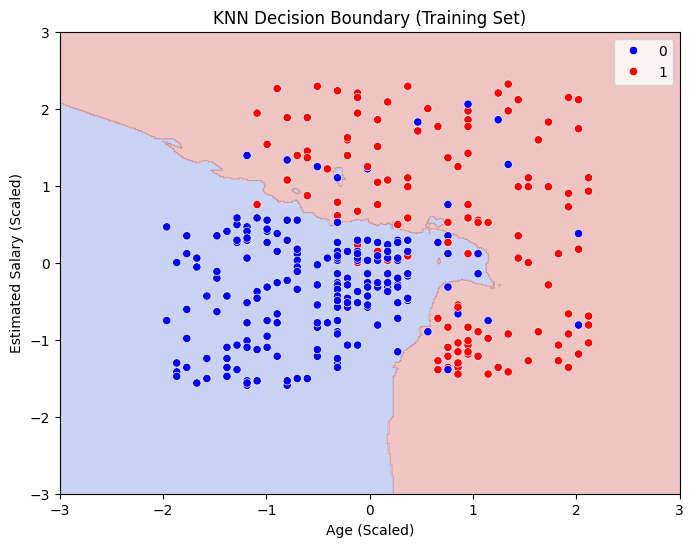

In [44]:
# 5. Visualize the decision boundary and the training points
plt.figure(figsize=(8, 6))
plt.contourf(x1, x2, Z, cmap=plt.cm.coolwarm, alpha=0.3)
sns.scatterplot(
    x=X_train_scaled[:, 0],
    y=X_train_scaled[:, 1],
    hue=y_train,
    palette={0: "blue", 1: "red"},
    marker="o",
)

plt.xlabel("Age (Scaled)")
plt.ylabel("Estimated Salary (Scaled)")
plt.title("KNN Decision Boundary (Training Set)")
plt.show()

In [45]:
!jupyter nbconvert "/content/drive/MyDrive/Colab Notebooks/KN_Classifier_prediction.ipynb" --to html

[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/KN_Classifier_prediction.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 424351 bytes to /content/drive/MyDrive/Colab Notebooks/KN_Classifier_prediction.html
